# Geographic Performance Analysis

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/dataset.csv', parse_dates=['order_date', 'shipping_date'])

df = df.drop_duplicates('order_id', ignore_index=True)

In [2]:
sns.set_theme()

from scripts import visualization_config

## Which regions experience the highest delivery delay rates?

For this question I took only the orders that had delays. Orders that were delivered on time (or in advance) are not in the calculation.

In [3]:
delivery_delay = df['days_for_shipping_real'] - df['days_for_shipment_scheduled']
delayed_shipments = df[delivery_delay > 0]

delayed_shipments['late_days'] = delayed_shipments['days_for_shipping_real'] - delayed_shipments['days_for_shipment_scheduled']

order_regions_average_delays = (
    delayed_shipments
    .groupby('order_region')['late_days']
    .agg(['mean', 'count'])
    .sort_values(by='mean',ascending=False)
)

for mode, row in order_regions_average_delays.iterrows():
    print(f"{mode}: {np.around(row['mean'], 2)} days ({int(row['count'])} values)")

Central Asia: 1.74 days (102 values)
South of  USA: 1.65 days (753 values)
Canada: 1.64 days (153 values)
South Asia: 1.64 days (1865 values)
Eastern Asia: 1.63 days (1818 values)
Eastern Europe: 1.63 days (723 values)
West Africa: 1.63 days (626 values)
Western Europe: 1.63 days (5585 values)
Northern Europe: 1.63 days (1996 values)
West of USA: 1.62 days (1451 values)
Southeast Asia: 1.62 days (2421 values)
Caribbean: 1.62 days (1487 values)
South America: 1.62 days (2696 values)
Central America: 1.61 days (5156 values)
East of USA: 1.61 days (1276 values)
Oceania: 1.61 days (2382 values)
Central Africa: 1.61 days (320 values)
North Africa: 1.6 days (578 values)
West Asia: 1.6 days (1132 values)
Southern Europe: 1.59 days (1895 values)
East Africa: 1.59 days (348 values)
US Center: 1.58 days (1071 values)
Southern Africa: 1.53 days (214 values)


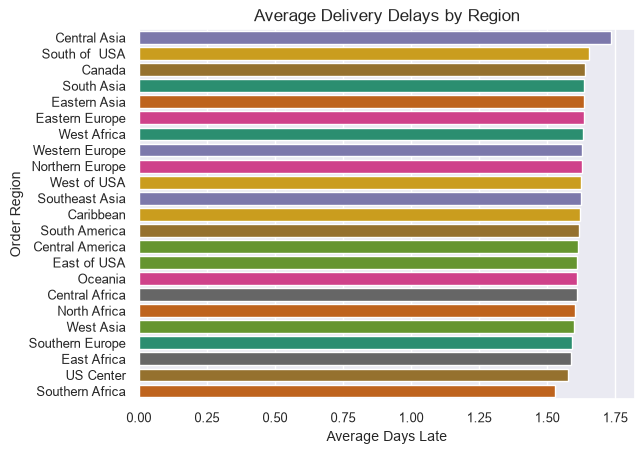

In [4]:
sns.barplot(data=delayed_shipments, x='late_days', y='order_region', hue='order_region', order=order_regions_average_delays.index, errorbar=None, legend=False, palette='Dark2')

plt.title('Average Delivery Delays by Region')
plt.xlabel('Average Days Late')
plt.ylabel('Order Region')

plt.savefig('../visualizations/average-delivery-delays-by-region.png', bbox_inches='tight')
plt.show()

There are 23 order regions in the dataset, and the variability is low in delivery delay rates. Central Asia experiences the highest average delivery delays - 1.74 days - and Southern Africa the least - 1.53 days.

It's worth noting though that these regions have among the lowest orders in general, so the values might be noise. 

- Central Asia has 102 orders
- Southern Africa has 214 orders

## Are there geographical markets with consistently longer shipping times?

In [5]:
markets_shipping_time_over_time = (
    df.groupby([
        df['order_date'].dt.to_period('M'),
        'market',
    ])['days_for_shipping_real']
    .agg(['mean', 'count'])
)

monthly_markets_rates = markets_shipping_time_over_time['mean'].unstack('market')

print(monthly_markets_rates)

market        Africa    Europe     LATAM  Pacific Asia      USCA
order_date                                                      
2015-01          NaN       NaN  3.554583           NaN       NaN
2015-02          NaN       NaN  3.513621           NaN       NaN
2015-03          NaN       NaN  3.457697           NaN       NaN
2015-04          NaN       NaN  3.565589           NaN       NaN
2015-05          NaN  3.700000  3.462895           NaN       NaN
2015-06          NaN  3.553604       NaN           NaN       NaN
2015-07          NaN  3.465962       NaN           NaN       NaN
2015-08          NaN  3.464243       NaN           NaN       NaN
2015-09          NaN  3.543452       NaN           NaN       NaN
2015-10          NaN  3.457870       NaN      3.531963       NaN
2015-11          NaN       NaN       NaN      3.515078       NaN
2015-12          NaN       NaN       NaN      3.462161       NaN
2016-01          NaN       NaN       NaN      3.517322       NaN
2016-02          NaN     

This grouped result strongly suggests that the data is synthethic, rather than real data. We can see that orders are divided into batches between markets (only 2017-01 has orders from all 5 markets at once). Therefore comparison of markets over time is **NOT** possible.

In [6]:
markets_shipping_time = df.groupby('market')['days_for_shipping_real'].describe()

print(markets_shipping_time)

                count      mean       std  min  25%  50%  75%  max
market                                                            
Africa         3689.0  3.496612  1.633453  0.0  2.0  3.0  5.0  6.0
Europe        17763.0  3.496650  1.626485  0.0  2.0  3.0  5.0  6.0
LATAM         16414.0  3.500670  1.615089  0.0  2.0  3.0  5.0  6.0
Pacific Asia  16853.0  3.511007  1.626230  0.0  2.0  3.0  5.0  6.0
USCA           8178.0  3.496454  1.625903  0.0  2.0  3.0  5.0  6.0


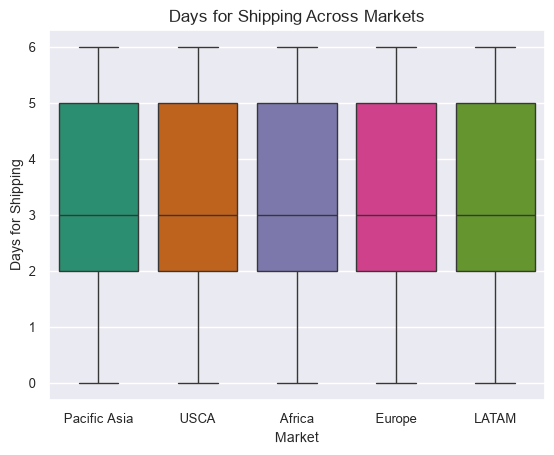

In [7]:
sns.boxplot(data=df, x='market', y='days_for_shipping_real', hue='market', legend=False, palette='Dark2')

plt.title('Days for Shipping Across Markets')

plt.xlabel('Market')
plt.ylabel('Days for Shipping')

plt.savefig('../visualizations/days-for-shipping-across-markets.png', bbox_inches='tight')
plt.show()

We get the same result when we compare days for shipping and markets. This suggests that there is no difference in days for shipping across different markets in this dataset.

## Are high-volume markets also experiencing poor shipping performance?

Number of orders in Europe: 17763
Number of orders in Pacific Asia: 16853
Number of orders in LATAM: 16414
Number of orders in USCA: 8178
Number of orders in Africa: 3689


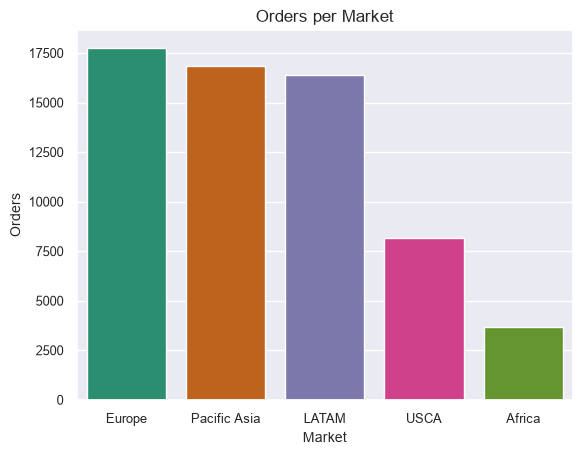

In [8]:
volume_per_market = df['market'].value_counts()

for market, count in volume_per_market.items():
    print(f'Number of orders in {market}: {count}')

sns.barplot(x=volume_per_market.index, y=volume_per_market.values, hue=volume_per_market.index, legend=False, palette='Dark2')

plt.title('Orders per Market')
plt.xlabel('Market')
plt.ylabel('Orders')

plt.savefig('../visualizations/order-per-market.png', bbox_inches='tight')
plt.show()

### Late Delivery Risk per Market
Late delivery risk indicates if sending is late or not.

In [9]:
late_delivery_risk_per_market = df.groupby('market')['late_delivery_risk'].mean() * 100

for market, risk in late_delivery_risk_per_market.items():
    print(f'Late delivery risk in {market}: {np.around(risk, 2)}%')

Late delivery risk in Africa: 56.55%
Late delivery risk in Europe: 57.42%
Late delivery risk in LATAM: 56.9%
Late delivery risk in Pacific Asia: 57.68%
Late delivery risk in USCA: 57.52%


From the table we can see that the risk doesn't vary a lot between markets.

### Days for Shipping per Market

We already saw in Q2 that days for shipping per markets are almost identical, which suggests that shipping performance doesn't depend on the volume of a market.


### Conclusion

The dataset doesn't contain other columns to further investigate this question.

The available data strongly suggests that high-volume and low-volume markets experience almost identical shipping performance.

## Which geographical areas should management prioritize?

Q1, Q2 and Q3 all answer questions about shipping and delivery in different markets/regions.

For this question I wanted to explore more of the business weight: sales and profit in different markets.

I'm loading the dataset again to calculate profit and sales for all items, not just per order.

In [10]:
df_full = pd.read_csv('../data/processed/dataset.csv', parse_dates=['order_date', 'shipping_date'])

In [11]:
details_by_market = df_full.groupby(['market', 'order_id']).agg(
    profit=('order_item_profit', 'sum'),
    revenue=('sales', 'sum'),
    items=('order_item_profit', 'count')
)

average_profit_per_market = (
    details_by_market
    .groupby('market')
    .agg(
        avg_profit=('profit', 'mean'),
        orders=('profit', 'count'),
        avg_items_per_order=('items', 'mean')
    )
    .sort_values('avg_profit', ascending=False)
)

for market, row in average_profit_per_market.iterrows():
    print(
        f'{market} ({int(row['orders'])} orders): \n'
        f'Average profits: ${np.around(row['avg_profit'], 2)}\n'
        f'Average items per order: {np.around(row['avg_items_per_order'], 2)}\n'
    )

USCA (8178 orders): 
Average profits: $65.94
Average items per order: 3.01

LATAM (16414 orders): 
Average profits: $65.13
Average items per order: 3.0

Africa (3689 orders): 
Average profits: $65.07
Average items per order: 3.02

Europe (17763 orders): 
Average profits: $63.72
Average items per order: 2.71

Pacific Asia (16853 orders): 
Average profits: $49.02
Average items per order: 2.35



The results show us that the top four markets have similar average profits (difference of 2$), and Pacific Asia is the clear outlier.

Pacific Asia has the lowest average profits (16.92$ less than USCA), and the lowest average items per order (0.66 items per order less than USCA).

Profit per item is similar in all markets, so Pacific Asia's lower average profit is a direct product of lower average items per order.

In [12]:
profit_and_revenue_by_market = (
    details_by_market
    .groupby('market')
    .agg(
        profit=('profit', 'sum'),
        revenue=('revenue', 'sum')
    )
    .sort_values('profit', ascending=False)
)

global_profit = details_by_market['profit'].sum()
global_revenue = details_by_market['revenue'].sum()

print(f'Global profit: ${global_profit:,.0f}')
print(f'Global revenue: ${global_revenue:,.0f} \n')

for market, row in profit_and_revenue_by_market.iterrows():
    print(
        f'{market}:\n'
        f'Profit: ${row['profit']:,.0f} ({(row['profit'] / global_profit):.1%} of global profit)\n'
        f'Revenue: ${row['revenue']:,.0f} ({(row['revenue'] / global_revenue):.1%} of global revenue)\n'
    )

Global profit: $3,806,421
Global revenue: $35,214,430 

Europe:
Profit: $1,131,938 (29.7% of global profit)
Revenue: $10,405,371 (29.5% of global revenue)

LATAM:
Profit: $1,069,051 (28.1% of global profit)
Revenue: $9,824,330 (27.9% of global revenue)

Pacific Asia:
Profit: $826,167 (21.7% of global profit)
Revenue: $7,942,352 (22.6% of global revenue)

USCA:
Profit: $539,223 (14.2% of global profit)
Revenue: $4,836,414 (13.7% of global revenue)

Africa:
Profit: $240,041 (6.3% of global profit)
Revenue: $2,205,963 (6.3% of global revenue)



### Conclusion

Europe and LATAM matter the most to the business. Together they bring in 57.8% of the total profit, and 57.4% of total revenue.

Profitability is almost the same everywhere. The differences between markets come from volume (number of orders) and basket size (number of items per order).

That's the reason why Pacific Asia stands out - the orders contain fewer items (2.35 compared to around 3 for other markets).

Shipping performance doesn't change the picture. About 57% of orders arrive late in every market. Which means late deliveries are a company-wide issue, not related to geography.

#### Priorities:

1. **Protect** Europe and LATAM. They bring the majority of the profit, so service problems there would cost the most.
2. **Grow basket size** in Pacific Asia.
3. **Lower priority** USCA and Africa. Their profit per order is good, but their volumes are smaller.
4. **Bonus**: **Fix late deliveries globally**.

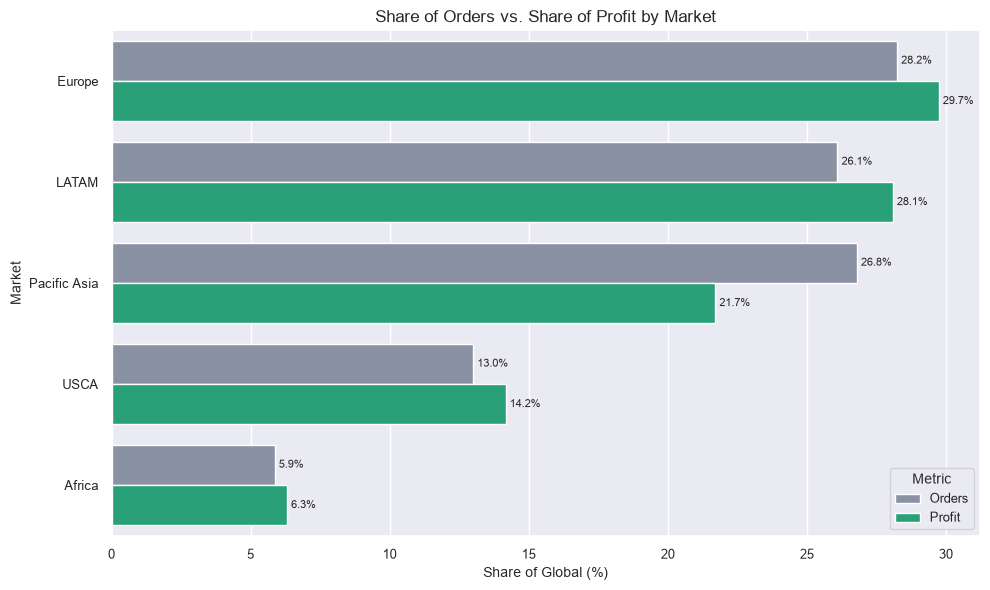

In [13]:
volume_share_per_market = volume_per_market / df['market'].count() * 100
profit_share_per_market = details_by_market.groupby('market')['profit'].sum() / global_profit * 100

market_shares = pd.DataFrame({'Orders': volume_share_per_market, 'Profit': profit_share_per_market}).reset_index()
market_shares = pd.melt(market_shares, id_vars='market', var_name='metric', value_name='share')

market_order = profit_share_per_market.sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(data=market_shares, x='share', y='market', hue='metric', order=market_order, palette={'Orders': '#868FA6', 'Profit': "#16B47F"})

plt.title('Share of Orders vs. Share of Profit by Market')
plt.xlabel('Share of Global (%)')
plt.ylabel('Market')
plt.legend(title='Metric')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=8)

plt.tight_layout()

plt.savefig('../visualizations/orders-share-vs-profit-share-by-market.png', bbox_inches='tight')
plt.show()